In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [3]:
df = pd.read_csv("uber.csv")
df = df.dropna().copy()
df = df[(df["fare_amount"] > 0) & (df["fare_amount"] < 100)]
df = df[df["pickup_latitude"].between(-90, 90) & df["dropoff_latitude"].between(-90, 90)]
df = df[df["pickup_longitude"].between(-180, 180) & df["dropoff_longitude"].between(-180, 180)]
if "pickup_datetime" in df.columns:
    dt = pd.to_datetime(df["pickup_datetime"], errors="coerce", utc=True)
    df["hour"] = dt.dt.hour
    df["day"] = dt.dt.day
    df["month"] = dt.dt.month
    df["year"] = dt.dt.year
    df["weekday"] = dt.dt.dayofweek
    df = df.dropna(subset=["hour"])
df = df.drop(columns=["key", "pickup_datetime"], errors="ignore")
display(df.head())
display(df.describe())

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,weekday
0,24238194,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3
1,27835199,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4
2,44984355,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0
3,25894730,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4
4,17610152,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,weekday
count,1.998750e+05,199875.000000,199875.000000,199875.000000,199875.000000,199875.000000,199875.000000,199875.000000,199875.000000,199875.000000,199875.000000,199875.000000
mean,2.771237e+07,11.303770,-72.503947,39.919100,-72.514492,39.923575,1.684623,13.492418,15.705191,6.281921,2011.741959,3.048200
std,1.601400e+07,9.426274,10.442762,6.126896,10.402419,6.112830,1.386135,6.514831,8.687510,3.438982,1.856299,1.947025
min,1.000000e+00,0.010000,-93.824668,-74.015515,-75.458979,-74.015750,0.000000,0.000000,1.000000,1.000000,2009.000000,0.000000
25%,1.382523e+07,6.000000,-73.992065,40.734803,-73.991403,40.733835,1.000000,9.000000,8.000000,3.000000,2010.000000,1.000000
50%,2.774512e+07,8.500000,-73.981825,40.752592,-73.980092,40.753040,1.000000,14.000000,16.000000,6.000000,2012.000000,3.000000
75%,4.155554e+07,12.500000,-73.967172,40.767155,-73.963671,40.767992,2.000000,19.000000,23.000000,9.000000,2013.000000,5.000000
max,5.542357e+07,99.200000,40.808425,48.018760,40.831932,45.031598,208.000000,23.000000,31.000000,12.000000,2015.000000,6.000000


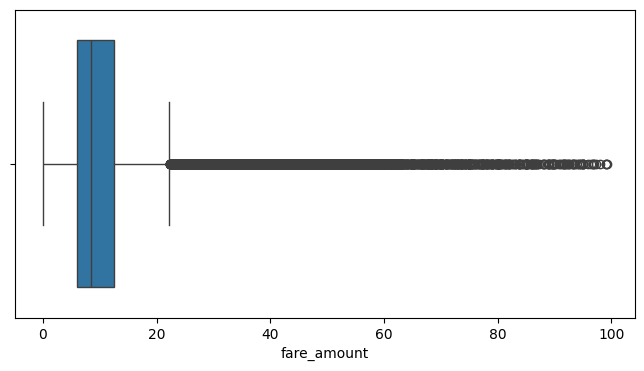

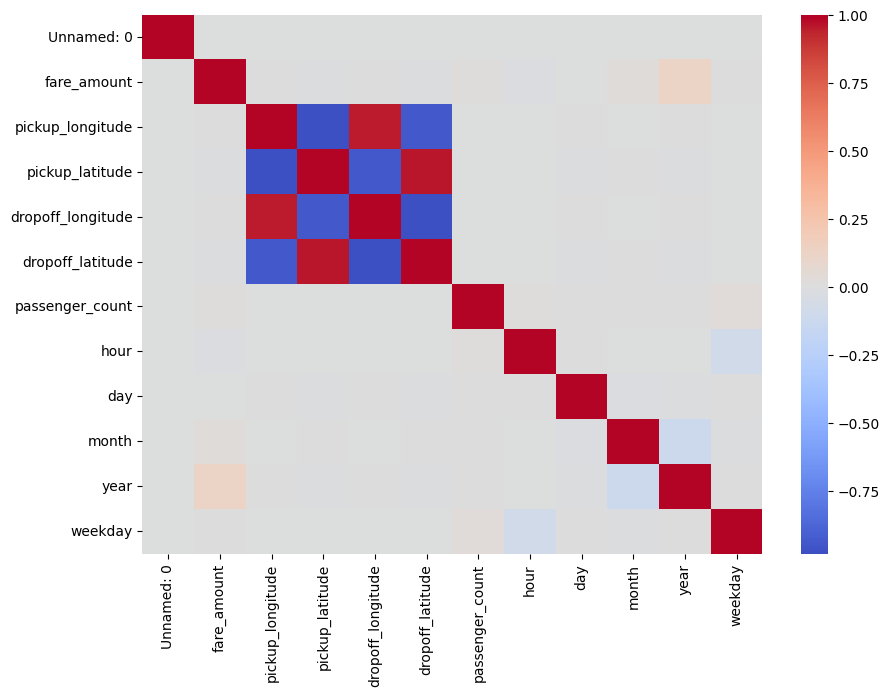

In [4]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.show()
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include=np.number).corr(), cmap="coolwarm", center=0)
plt.show()

In [6]:
from math import radians, sin, cos, asin, sqrt
def distance(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(radians, [lon1, lat1, lon2, lat2])
    a = sin((lat2-lat1)/2)**2 + cos(lat1)*cos(lat2)*sin((lon2-lon1)/2)**2
    return 6371 * 2 * asin(sqrt(a))
df["distance_km"] = df.apply(lambda r: distance(r.pickup_longitude, r.pickup_latitude, r.dropoff_longitude, r.dropoff_latitude), axis=1)
df = df[df["distance_km"].between(0, 200)]
features = ["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "distance_km"]
features += [c for c in ["hour", "day", "month", "year", "weekday", "passenger_count"] if c in df.columns]
X = df[features].replace([np.inf, -np.inf], np.nan)
y = df["fare_amount"]
valid = X.notna().all(axis=1) & y.notna()
X, y = X.loc[valid], y.loc[valid]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7)

In [7]:
models = {"Linear Regression": LinearRegression(), "Random Forest": RandomForestRegressor(n_estimators=100, random_state=7, n_jobs=-1)}
results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append([name, r2_score(y_test, pred), np.sqrt(mean_squared_error(y_test, pred)), mean_absolute_error(y_test, pred)])
display(pd.DataFrame(results, columns=["Model", "R2", "RMSE", "MAE"]))

,Model,R2,RMSE,MAE
0,Linear Regression,0.639981,5.62317,2.738516
1,Random Forest,0.828444,3.88170,1.906301


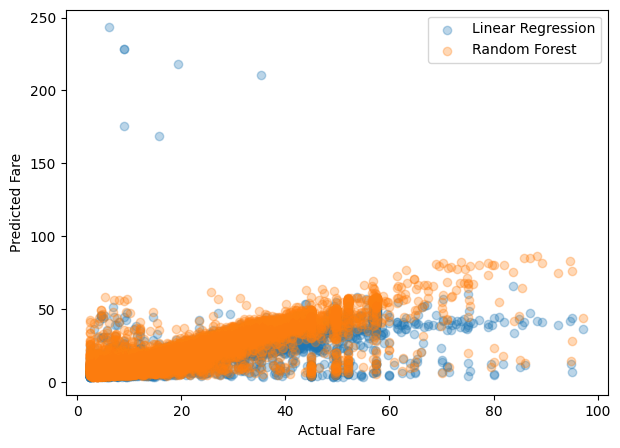

In [8]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions["Linear Regression"], alpha=0.3, label="Linear Regression")
plt.scatter(y_test, predictions["Random Forest"], alpha=0.3, label="Random Forest")
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.legend()
plt.show()